# Smartphone Battery Drain Prediction Using Linear Regression

## Introduction

Smartphones have become an essential part of daily life, and battery consumption depends on several factors such as application usage, screen time, data consumption, and the number of installed applications.

This project aims to analyze smartphone usage patterns and predict daily battery consumption using Linear Regression.

Both Simple Linear Regression and Multiple Linear Regression are implemented to understand the relationship between smartphone usage characteristics and battery drain.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Loading the Dataset

In [3]:
df = pd.read_csv(r"C:\Users\dell\Desktop\mitali\user_behavior_dataset.csv")

## Initial Dataset Exploration

In [4]:
df.head()

,User ID,Device Model,Operating System,App Usage Time (min/day),Screen On Time (hours/day),Battery Drain (mAh/day),Number of Apps Installed,Data Usage (MB/day),Age,Gender,User Behavior Class
0,1,Google Pixel 5,Android,393,6.4,1872,67,1122,40,Male,4
1,2,OnePlus 9,Android,268,4.7,1331,42,944,47,Female,3
2,3,Xiaomi Mi 11,Android,154,4.0,761,32,322,42,Male,2
3,4,Google Pixel 5,Android,239,4.8,1676,56,871,20,Male,3
4,5,iPhone 12,iOS,187,4.3,1367,58,988,31,Female,3


In [5]:
df.tail()

,User ID,Device Model,Operating System,App Usage Time (min/day),Screen On Time (hours/day),Battery Drain (mAh/day),Number of Apps Installed,Data Usage (MB/day),Age,Gender,User Behavior Class
695,696,iPhone 12,iOS,92,3.9,1082,26,381,22,Male,2
696,697,Xiaomi Mi 11,Android,316,6.8,1965,68,1201,59,Male,4
697,698,Google Pixel 5,Android,99,3.1,942,22,457,50,Female,2
698,699,Samsung Galaxy S21,Android,62,1.7,431,13,224,44,Male,1
699,700,OnePlus 9,Android,212,5.4,1306,49,828,23,Female,3


#  Exploratory Data Analysis (EDA)

##  Checking Missing Values

In [6]:
df.isnull().sum()

User ID                       0
Device Model                  0
Operating System              0
App Usage Time (min/day)      0
Screen On Time (hours/day)    0
Battery Drain (mAh/day)       0
Number of Apps Installed      0
Data Usage (MB/day)           0
Age                           0
Gender                        0
User Behavior Class           0
dtype: int64

## Checking Duplicate values

In [7]:
df.duplicated().sum()

np.int64(0)

## Dataset Structure and Data Types

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   User ID                     700 non-null    int64  
 1   Device Model                700 non-null    object 
 2   Operating System            700 non-null    object 
 3   App Usage Time (min/day)    700 non-null    int64  
 4   Screen On Time (hours/day)  700 non-null    float64
 5   Battery Drain (mAh/day)     700 non-null    int64  
 6   Number of Apps Installed    700 non-null    int64  
 7   Data Usage (MB/day)         700 non-null    int64  
 8   Age                         700 non-null    int64  
 9   Gender                      700 non-null    object 
 10  User Behavior Class         700 non-null    int64  
dtypes: float64(1), int64(7), object(3)
memory usage: 60.3+ KB


In [9]:
features = [
    'App Usage Time (min/day)',
    'Screen On Time (hours/day)',
    'Data Usage (MB/day)',
    'Number of Apps Installed'
]

target = 'Battery Drain (mAh/day)'

X = df[features]
y = df[target]

print("Independent Variables:")
display(X.head())

print("\nDependent Variable:")
display(y.head())

Independent Variables:


,App Usage Time (min/day),Screen On Time (hours/day),Data Usage (MB/day),Number of Apps Installed
0,393,6.4,1122,67
1,268,4.7,944,42
2,154,4.0,322,32
3,239,4.8,871,56
4,187,4.3,988,58



Dependent Variable:


0    1872
1    1331
2     761
3    1676
4    1367
Name: Battery Drain (mAh/day), dtype: int64

In [10]:
print("Statistical Summary:")
display(df[features + [target]].describe())

Statistical Summary:


,App Usage Time (min/day),Screen On Time (hours/day),Data Usage (MB/day),Number of Apps Installed,Battery Drain (mAh/day)
count,700.000000,700.000000,700.000000,700.000000,700.000000
mean,271.128571,5.272714,929.742857,50.681429,1525.158571
std,177.199484,3.068584,640.451729,26.943324,819.136414
min,30.000000,1.000000,102.000000,10.000000,302.000000
25%,113.250000,2.500000,373.000000,26.000000,722.250000
50%,227.500000,4.900000,823.500000,49.000000,1502.500000
75%,434.250000,7.400000,1341.000000,74.000000,2229.500000
max,598.000000,12.000000,2497.000000,99.000000,2993.000000


## Dataset Features - Units and Ranges

Include:
1.App Usage Time: More time spent using applications can increase battery consumption.
2.Screen On Time: Keeping the screen ON consumes battery power.
3.Data Usage: Internet activities such as browsing, streaming and downloading can consume battery.
4.Number of Apps Installed: More installed applications may increase background activities and battery usage

In [11]:
correlation = df[features + [target]].corr()

print("Correlation with Battery Drain:")
display(correlation[[target]].sort_values(
    by=target, ascending=False
))

Correlation with Battery Drain:


,Battery Drain (mAh/day)
Battery Drain (mAh/day),1.000000
Number of Apps Installed,0.961853
App Usage Time (min/day),0.956385
Screen On Time (hours/day),0.948983
Data Usage (MB/day),0.932276


## Multicollinearity - Feature Correlation Analysis

Include:
- Correlation among independent variables.
- Display a separate feature-to-feature correlation table.
- Identify highly correlated feature pairs.
- Explain whether two features may be carrying similar information.

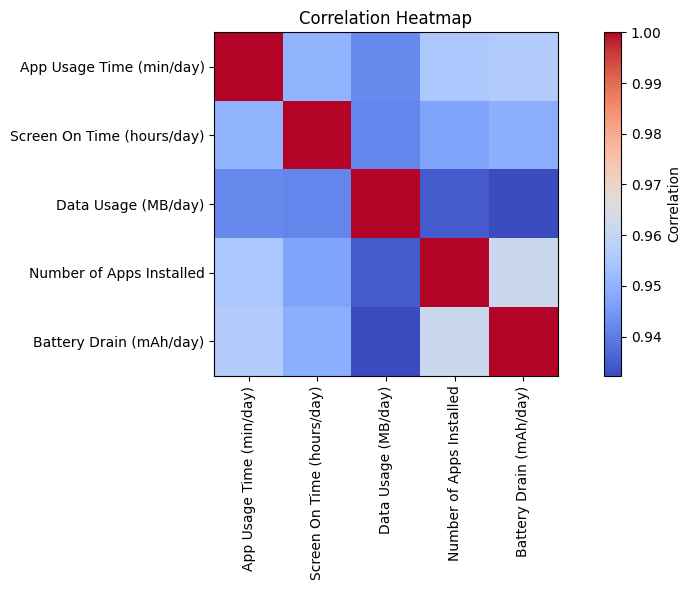

In [35]:
plt.figure(figsize=(10, 6))

plt.imshow(correlation, cmap='coolwarm', interpolation='nearest')
plt.colorbar(label='Correlation')

plt.xticks(range(len(correlation.columns)),
           correlation.columns, rotation=90)

plt.yticks(range(len(correlation.columns)),
           correlation.columns)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

Correlation Between Independent Variables:


,App Usage Time (min/day),Screen On Time (hours/day),Data Usage (MB/day),Number of Apps Installed
App Usage Time (min/day),1.000000,0.950333,0.942308,0.955253
Screen On Time (hours/day),0.950333,1.000000,0.941322,0.946975
Data Usage (MB/day),0.942308,0.941322,1.000000,0.934800
Number of Apps Installed,0.955253,0.946975,0.934800,1.000000



Highly Correlated Feature Pairs:
App Usage Time (min/day) and Screen On Time (hours/day): Correlation = 0.9503
App Usage Time (min/day) and Data Usage (MB/day): Correlation = 0.9423
App Usage Time (min/day) and Number of Apps Installed: Correlation = 0.9553
Screen On Time (hours/day) and Data Usage (MB/day): Correlation = 0.9413
Screen On Time (hours/day) and Number of Apps Installed: Correlation = 0.9470
Data Usage (MB/day) and Number of Apps Installed: Correlation = 0.9348


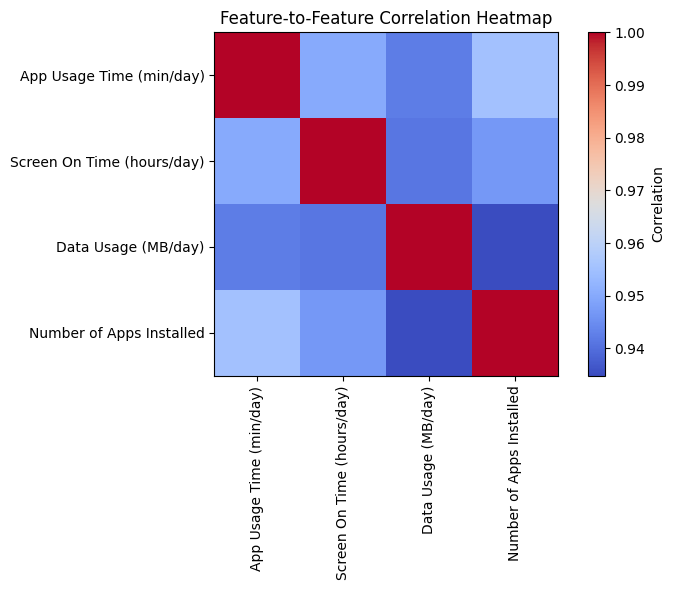

In [36]:
feature_correlation = df[features].corr()

print("Correlation Between Independent Variables:")
display(feature_correlation)

print("\nHighly Correlated Feature Pairs:")

for i in range(len(features)):
    for j in range(i + 1, len(features)):

        corr_value = feature_correlation.iloc[i, j]

        if abs(corr_value) >= 0.7:
            print(
                f"{features[i]} and {features[j]}: "
                f"Correlation = {corr_value:.4f}"
            )

        else:
            print(
                f"{features[i]} and {features[j]}: "
                f"Correlation = {corr_value:.4f}"
            )

# Visualize feature-to-feature correlation
plt.figure(figsize=(8, 6))

plt.imshow(
    feature_correlation,
    cmap='coolwarm',
    interpolation='nearest'
)

plt.colorbar(label='Correlation')

plt.xticks(
    range(len(features)),
    features,
    rotation=90
)

plt.yticks(
    range(len(features)),
    features
)

plt.title("Feature-to-Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

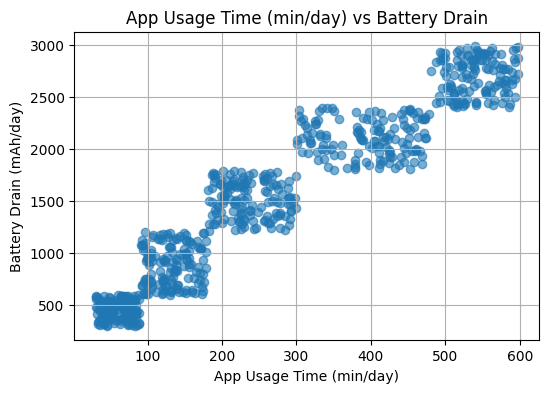

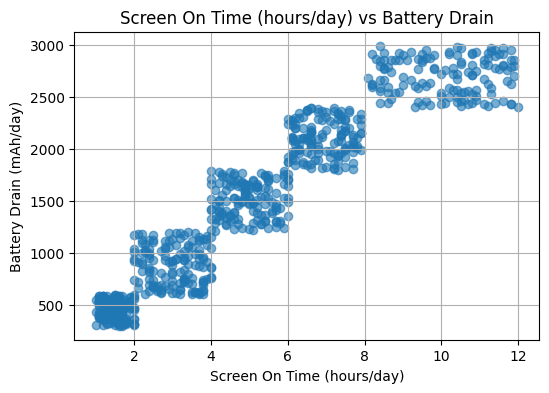

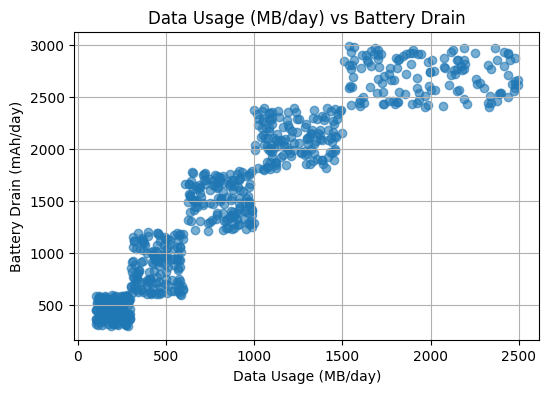

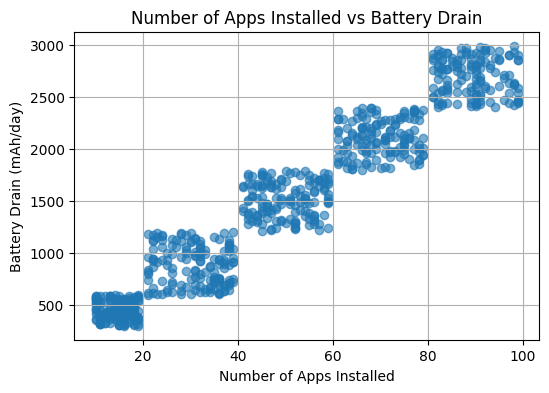

In [13]:
for feature in features:

    plt.figure(figsize=(6, 4))

    plt.scatter(df[feature], y, alpha=0.6)

    plt.xlabel(feature)
    plt.ylabel("Battery Drain (mAh/day)")

    plt.title(f"{feature} vs Battery Drain")

    plt.grid(True)
    plt.show()

# Manual Multiple Linear Regression Using Normal Equation

Use two features:
- X1 = Screen On Time (hours/day)
- X2 = App Usage Time (min/day)
- Y = Battery Drain (mAh/day)

In [14]:
from sklearn.model_selection import train_test_split

In [15]:
X_simple = df[['Screen On Time (hours/day)']]
y = df['Battery Drain (mAh/day)']

X_train, X_test, y_train, y_test = train_test_split(
    X_simple,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 560
Testing records: 140


In [16]:
from sklearn.linear_model import LinearRegression

In [17]:
simple_model = LinearRegression()

simple_model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [18]:
print("Intercept:", simple_model.intercept_)

print("Coefficient:", simple_model.coef_[0])

Intercept: 184.13665682542387
Coefficient: 254.44924451031176


In [19]:
y_pred_simple = simple_model.predict(X_test)

results = pd.DataFrame({
    'Actual Battery Drain': y_test.values,
    'Predicted Battery Drain': y_pred_simple
})

display(results.head(10))

,Actual Battery Drain,Predicted Battery Drain
0,2375,1838.056746
1,369,514.920675
2,437,464.030826
3,893,1049.264088
4,1489,1710.832124
5,714,1049.264088
6,636,1151.043786
7,415,489.475750
8,2113,1838.056746
9,1326,1227.378559


In [20]:
from sklearn.metrics import mean_squared_error, mean_absolute_error ,r2_score

In [21]:
mse_simple = mean_squared_error(y_test, y_pred_simple)

mae_simple = mean_absolute_error(y_test, y_pred_simple)

r2_simple = r2_score(y_test, y_pred_simple)

print("Simple Linear Regression Results")
print("---------------------------------")
print("Mean Squared Error:", mse_simple)
print("Mean Absolute Error:", mae_simple)
print("R2 Score:", r2_simple)

Simple Linear Regression Results
---------------------------------
Mean Squared Error: 66751.93949794697
Mean Absolute Error: 205.7835278075701
R2 Score: 0.892433026042035


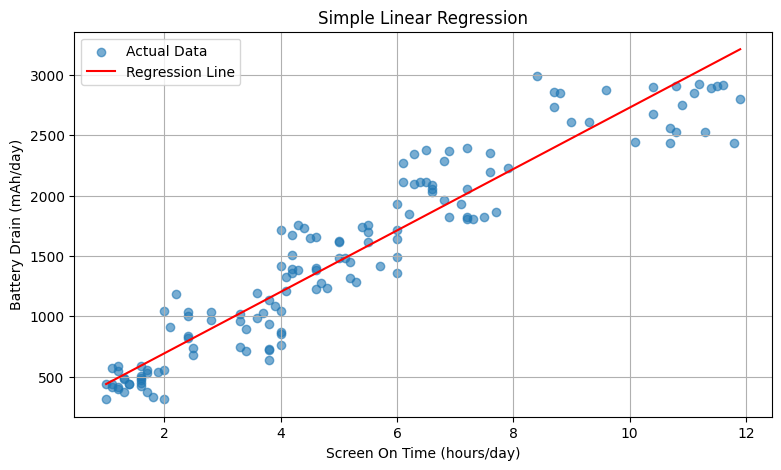

In [22]:
plt.figure(figsize=(9, 5))

plt.scatter(X_test, y_test, alpha=0.6, label='Actual Data')

sorted_indices = np.argsort(
    X_test['Screen On Time (hours/day)'].values
)

x_sorted = X_test.iloc[sorted_indices]
y_sorted = y_pred_simple[sorted_indices]

plt.plot(
    x_sorted['Screen On Time (hours/day)'],
    y_sorted,
    color='red',
    label='Regression Line'
)

plt.xlabel("Screen On Time (hours/day)")
plt.ylabel("Battery Drain (mAh/day)")
plt.title("Simple Linear Regression")
plt.legend()
plt.grid(True)
plt.show()

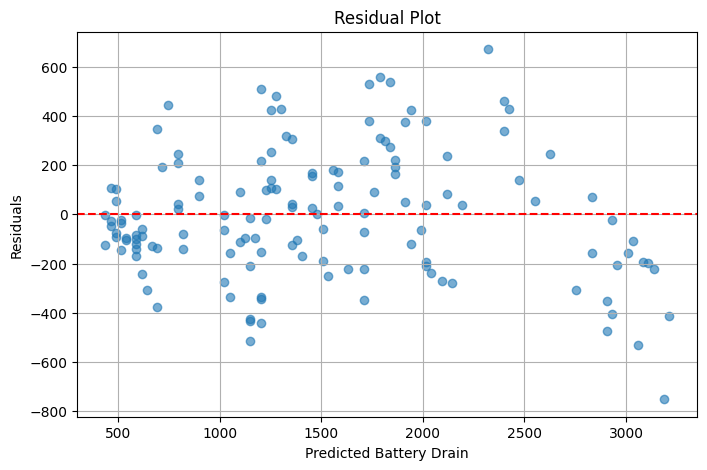

In [23]:
residuals = y_test - y_pred_simple

plt.figure(figsize=(8, 5))

plt.scatter(y_pred_simple, residuals, alpha=0.6)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Battery Drain")
plt.ylabel("Residuals")

plt.title("Residual Plot")
plt.grid(True)

plt.show()

#  Multiple Linear Regression

In [24]:
X = df[[
    'App Usage Time (min/day)',
    'Screen On Time (hours/day)',
    'Data Usage (MB/day)',
    'Number of Apps Installed'
]]

y = df['Battery Drain (mAh/day)']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (560, 4)
Testing data: (140, 4)


In [25]:
multiple_model = LinearRegression()

multiple_model.fit(X_train, y_train)

print("Multiple Linear Regression trained successfully!")

Multiple Linear Regression trained successfully!


In [26]:
print("Intercept:", multiple_model.intercept_)

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': multiple_model.coef_
})

display(coefficients)

Intercept: 138.09033487713464


,Feature,Coefficient
0,App Usage Time (min/day),1.400023
1,Screen On Time (hours/day),54.253409
2,Data Usage (MB/day),0.072643
3,Number of Apps Installed,12.832561


In [27]:
y_pred_multiple = multiple_model.predict(X_test)

multiple_results = pd.DataFrame({
    'Actual Battery Drain': y_test.values,
    'Predicted Battery Drain': y_pred_multiple
})

display(multiple_results.head(10))

,Actual Battery Drain,Predicted Battery Drain
0,2375,2038.572969
1,369,494.842546
2,437,497.014699
3,893,1041.540811
4,1489,1614.220822
5,714,1028.718488
6,636,926.796239
7,415,459.727863
8,2113,2008.316669
9,1326,1488.138634


In [28]:
mse_multiple = mean_squared_error(
    y_test, y_pred_multiple
)

mae_multiple = mean_absolute_error(
    y_test, y_pred_multiple
)

r2_multiple = r2_score(
    y_test, y_pred_multiple
)

print("Multiple Linear Regression Results")
print("----------------------------------")
print("MSE:", mse_multiple)
print("MAE:", mae_multiple)
print("R2 Score:", r2_multiple)

Multiple Linear Regression Results
----------------------------------
MSE: 35191.74927357006
MAE: 157.31067269466593
R2 Score: 0.9432904870462713


In [29]:
comparison = pd.DataFrame({
    'Metric': ['MSE', 'MAE', 'R2 Score'],
    'Simple Linear Regression': [
        mse_simple,
        mae_simple,
        r2_simple
    ],
    'Multiple Linear Regression': [
        mse_multiple,
        mae_multiple,
        r2_multiple
    ]
})

display(comparison)

,Metric,Simple Linear Regression,Multiple Linear Regression
0,MSE,66751.939498,35191.749274
1,MAE,205.783528,157.310673
2,R2 Score,0.892433,0.943290


In [30]:
multiple_residuals = y_test - y_pred_multiple

residual_df = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred_multiple,
    'Residuals': multiple_residuals
})

display(residual_df.head(10))

,Actual,Predicted,Residuals
158,2375,2038.572969,336.427031
500,369,494.842546,-125.842546
396,437,497.014699,-60.014699
155,893,1041.540811,-148.540811
321,1489,1614.220822,-125.220822
212,714,1028.718488,-314.718488
234,636,926.796239,-290.796239
289,415,459.727863,-44.727863
300,2113,2008.316669,104.683331
356,1326,1488.138634,-162.138634


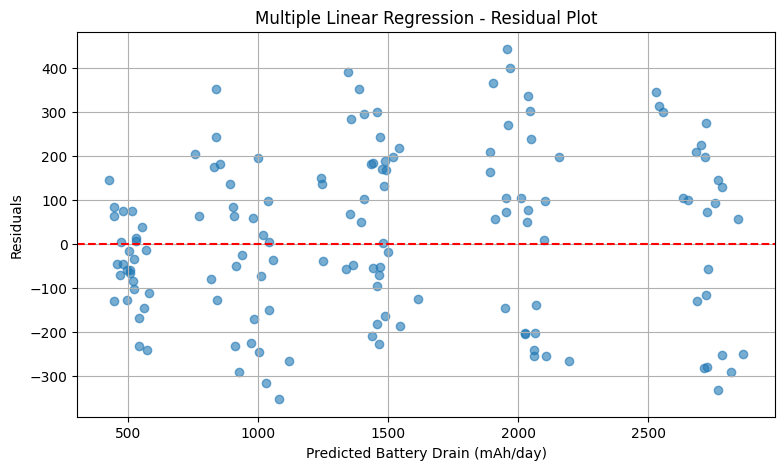

In [31]:
plt.figure(figsize=(9, 5))

plt.scatter(
    y_pred_multiple,
    multiple_residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.xlabel("Predicted Battery Drain (mAh/day)")
plt.ylabel("Residuals")

plt.title("Multiple Linear Regression - Residual Plot")

plt.grid(True)
plt.show()

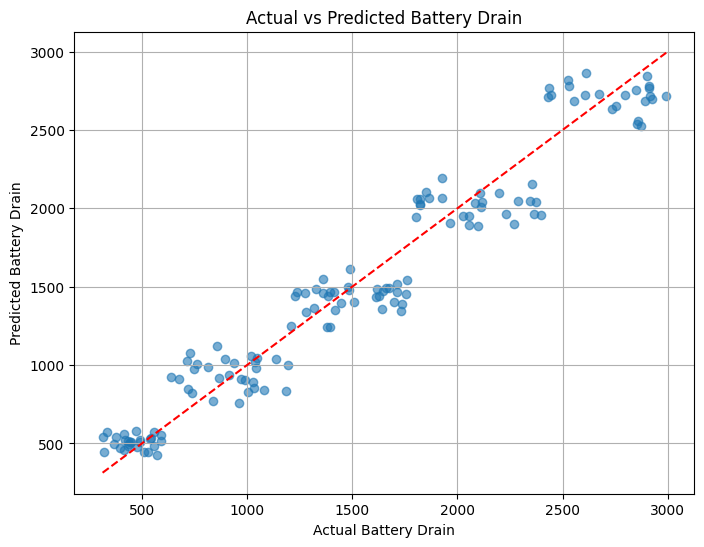

In [32]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_multiple,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)

plt.xlabel("Actual Battery Drain")
plt.ylabel("Predicted Battery Drain")

plt.title("Actual vs Predicted Battery Drain")

plt.grid(True)
plt.show()

In [33]:
print("Intercept:", multiple_model.intercept_)

for feature, coefficient in zip(features, multiple_model.coef_):
    print(f"{feature}: {coefficient:.4f}")

Intercept: 138.09033487713464
App Usage Time (min/day): 1.4000
Screen On Time (hours/day): 54.2534
Data Usage (MB/day): 0.0726
Number of Apps Installed: 12.8326


In [34]:
new_user = pd.DataFrame({
    'App Usage Time (min/day)': [300],
    'Screen On Time (hours/day)': [5.5],
    'Data Usage (MB/day)': [1200],
    'Number of Apps Installed': [50]
})

predicted_drain = multiple_model.predict(new_user)

print("Predicted Battery Drain:",
      round(predicted_drain[0], 2), "mAh/day")

Predicted Battery Drain: 1585.29 mAh/day


## Conclusion

The project successfully implemented Simple Linear Regression and Multiple Linear Regression to predict smartphone battery consumption based on user usage patterns.

The dataset contained 700 records and 11 attributes. Four independent variables were selected: App Usage Time, Screen On Time, Data Usage, and Number of Apps Installed. Battery Drain (mAh/day) was considered the dependent variable.

Initially, Simple Linear Regression was implemented using Screen On Time as the predictor, achieving an R² score of 89.24%.

Multiple Linear Regression was then implemented using all four independent variables. It achieved an R² score of 94.33%, an MSE of 35,191.75, and an MAE of 157.31.

The comparison indicates that Multiple Linear Regression performed better than Simple Linear Regression on the selected test dataset.

The project demonstrates regression problem formulation, coefficient interpretation, intercepts, residual analysis, least-squares fitting, MSE calculation, model evaluation, and prediction.

Thus, Linear Regression can be used to estimate smartphone battery consumption based on usage-related features. However, the model's assumptions and performance on unseen data should also be considered before practical deployment.